# pixel2dag · Notebook 04 — El clasificador y el atajo

**Objetivo:** entrenar un modelo que detecte la retinopatía y descubrir que **aprende un atajo**: se fija en el escáner del hospital, no en las lesiones.

**Aprenderás:**
- lo básico de `scikit-learn`: `fit`, `predict` y `score`;
- a convertir imágenes en algo que un modelo pueda usar;
- por qué la *accuracy* puede engañar y qué usar en su lugar;
- a "preguntarle" al modelo dónde mira.

**Duración:** unos 50–60 minutos. **Necesitas además:** `pip install scikit-learn`.

### Código de los notebooks 01–03

Es la versión resuelta. Al final, carga los datos que guardaste en el notebook 03 desde la carpeta `datos/`. Si no los encuentra, los genera (tarda menos de un minuto). Solo ejecútala.

In [2]:
import random, math
import numpy as np
import matplotlib.pyplot as plt

# ---------- notebook 01 (+ mundos del 03) ----------
def dado(semilla, variable):
    return random.Random(f"{semilla}-{variable}")

def lanzar_monedas(rng, n, p):
    return sum(rng.random() < p for _ in range(n))

def sigmoide(x):
    return 1 / (1 + math.exp(-x))

MUNDO_ENTRENAMIENTO = {"base": -1.0, "coef_hospital_A": 1.5}
MUNDO_SIN_CONFUSION = {"base": -1.0, "coef_hospital_A": 0.0}
MUNDO_INVERTIDO     = {"base": 0.5,  "coef_hospital_A": -1.5}

def prob_gravedad(edad, hospital, mundo=MUNDO_ENTRENAMIENTO):
    return sigmoide(mundo["base"] + 0.05 * (edad - 60) + mundo["coef_hospital_A"] * (hospital == "A"))

PROB_MA = [0.0, 0.075, 0.2, 0.375, 0.625]
PROB_EX = [0.0, 0.0, 0.1, 0.25, 0.5]

def simular_paciente(semilla, do=None, mundo=MUNDO_ENTRENAMIENTO):
    do = do or {}
    hospital = do["hospital"] if "hospital" in do else ("A" if dado(semilla, "hospital").random() < 0.5 else "B")
    edad = do["edad"] if "edad" in do else dado(semilla, "edad").gauss(60, 10)
    gravedad = do["gravedad"] if "gravedad" in do else lanzar_monedas(dado(semilla, "gravedad"), 4, prob_gravedad(edad, hospital, mundo))
    n_ma = lanzar_monedas(dado(semilla, "ma"), 40, PROB_MA[gravedad])
    n_ex = lanzar_monedas(dado(semilla, "ex"), 20, PROB_EX[gravedad])
    return {"semilla": semilla, "hospital": hospital, "edad": edad, "gravedad": gravedad,
            "n_ma": n_ma, "n_ex": n_ex, "referable": int(gravedad >= 2)}

# ---------- notebook 02 (+ mancha rápida del 03) ----------
IMG = 64
C = (IMG - 1) / 2
R = IMG * 0.46
YY, XX = np.mgrid[0:IMG, 0:IMG]
D = np.sqrt((YY - C) ** 2 + (XX - C) ** 2)
MASCARA = D <= R
factor = 1 - 0.35 * (D / R) ** 2

def pintar_mancha(img, cy, cx, radio, color, alpha=1.0):
    m = int(math.ceil(3 * radio)) + 1
    y0, y1 = max(0, int(cy) - m), min(IMG, int(cy) + m + 1)
    x0, x1 = max(0, int(cx) - m), min(IMG, int(cx) + m + 1)
    img = img.copy()
    if y0 >= y1 or x0 >= x1:
        return img
    w = alpha * np.exp(-((YY[y0:y1, x0:x1] - cy) ** 2 + (XX[y0:y1, x0:x1] - cx) ** 2) / (2 * radio ** 2))
    img[y0:y1, x0:x1] = (1 - w[..., None]) * img[y0:y1, x0:x1] + w[..., None] * np.array(color)
    return img

def dibujar_vasos(img, semilla, ny, nx):
    rng = dado(semilla, "vasos")
    for _ in range(4):
        y, x = ny, nx
        angulo = rng.uniform(0, 2 * math.pi)
        grosor = 1.2
        for paso in range(60):
            angulo += rng.gauss(0, 0.18)
            y += math.sin(angulo)
            x += math.cos(angulo)
            if math.hypot(y - C, x - C) > R:
                break
            img = pintar_mancha(img, y, x, grosor, [0.55, 0.08, 0.05], 0.6)
            grosor = max(0.5, grosor * 0.99)
    return img

def fondo_de_ojo(semilla):
    lado = dado(semilla, "lado").choice([-1, 1])
    ny, nx = 32, C + lado * 16
    img = np.zeros((IMG, IMG, 3))
    img[MASCARA] = [0.8, 0.35, 0.15]
    img = img * factor[..., None]
    img = pintar_mancha(img, ny, nx, 4, [0.98, 0.85, 0.55], 0.95)
    img = dibujar_vasos(img, semilla, ny, nx)
    return img

def posicion_en_disco(rng):
    distancia = R * 0.9 * math.sqrt(rng.random())
    angulo = rng.uniform(0, 2 * math.pi)
    return C + distancia * math.sin(angulo), C + distancia * math.cos(angulo)

def dibujar_microaneurismas(img, semilla, n_ma):
    rng = dado(semilla, "pos_ma")
    for i in range(n_ma):
        y, x = posicion_en_disco(rng)
        img = pintar_mancha(img, y, x, 0.8, [0.35, 0, 0], 0.95)
    return img

def dibujar_exudados(img, semilla, n_ex):
    rng = dado(semilla, "pos_ex")
    for i in range(n_ex):
        y, x = posicion_en_disco(rng)
        radio = rng.uniform(0.9, 1.8)
        img = pintar_mancha(img, y, x, radio, [1.0, 0.92, 0.35], 0.9)
    return img

def efecto_escaner(img, hospital, semilla):
    rng_np = np.random.default_rng(dado(semilla, "ruido").randrange(2**32))
    if hospital == "A":
        img = img + rng_np.normal(0, 0.02, img.shape)
        img[2:7, 2:7] = 1.0
    else:
        img = img * 0.8 * factor[..., None]
        img = img + rng_np.normal(0, 0.05, img.shape)
    return np.clip(img, 0, 1)

def renderizar(paciente):
    s = paciente["semilla"]
    img = fondo_de_ojo(s)
    img = dibujar_microaneurismas(img, s, paciente["n_ma"])
    img = dibujar_exudados(img, s, paciente["n_ex"])
    img = efecto_escaner(img, paciente["hospital"], s)
    return img

# ---------- notebook 03 ----------
def generar_dataset(semillas, do=None, mundo=MUNDO_ENTRENAMIENTO):
    pacientes = [simular_paciente(s, do, mundo) for s in semillas]
    X = np.stack([renderizar(p) for p in pacientes]).astype(np.float32)
    return X, pacientes

# ---------- notebook 03: guardar / cargar ----------
import os
import pandas as pd

def guardar(nombre, X, pacientes, carpeta="datos"):
    os.makedirs(carpeta, exist_ok=True)
    X8 = (X * 255).round().astype(np.uint8)
    np.savez_compressed(f"{carpeta}/{nombre}.npz", X=X8)
    pd.DataFrame(pacientes).to_csv(f"{carpeta}/{nombre}.csv", index=False)

def cargar(nombre, carpeta="datos"):
    X = np.load(f"{carpeta}/{nombre}.npz")["X"].astype(np.float32) / 255
    tabla = pd.read_csv(f"{carpeta}/{nombre}.csv")
    return X, tabla

CONJUNTOS = {   # nombre: (semillas, mundo)
    "entrenamiento":      (range(0, 3000),          MUNDO_ENTRENAMIENTO),
    "test_iid":           (range(100000, 101000),   MUNDO_ENTRENAMIENTO),
    "test_sin_confusion": (range(200000, 201000),   MUNDO_SIN_CONFUSION),
    "test_invertido":     (range(300000, 301000),   MUNDO_INVERTIDO),
}

def cargar_o_generar(nombre):
    # Si ya existen los ficheros del notebook 03, los carga; si no, los genera y los guarda.
    if not os.path.exists(f"datos/{nombre}.npz"):
        print(f"  generando {nombre}...")
        semillas, mundo = CONJUNTOS[nombre]
        guardar(nombre, *generar_dataset(semillas, mundo=mundo))
    return cargar(nombre)

print("Cargando datos...")
X_tr, tabla_tr = cargar_o_generar("entrenamiento")
TEST = {
    "iid":           cargar_o_generar("test_iid"),
    "sin_confusion": cargar_o_generar("test_sin_confusion"),
    "invertido":     cargar_o_generar("test_invertido"),
}
print("✅ Entrenamiento:", X_tr.shape, "| Test:", {k: v[0].shape[0] for k, v in TEST.items()})

Cargando datos...
✅ Entrenamiento: (3000, 64, 64, 3) | Test: {'iid': 1000, 'sin_confusion': 1000, 'invertido': 1000}


---
## Parte 1 · `scikit-learn` en 5 minutos

Un **clasificador** aprende a predecir una etiqueta (por ejemplo, 0 o 1) a partir de unos números (las **características**). En `scikit-learn` todos los modelos funcionan igual:

| Método | Qué hace |
|---|---|
| `modelo.fit(X, y)` | **Entrena**: aprende a partir de los ejemplos `X` y sus etiquetas `y` |
| `modelo.predict(X)` | **Predice** la etiqueta de ejemplos nuevos |
| `modelo.score(X, y)` | Devuelve la **accuracy**: la fracción de aciertos |

`X` es una matriz de forma `(n_ejemplos, n_características)` e `y` un vector de longitud `n_ejemplos`.

### 🔍 Ejemplo: ¿aprueba el estudiante?

Usaremos **regresión logística**: la sigmoide del notebook 01, pero con los coeficientes **aprendidos de los datos** en lugar de puestos a mano.

In [3]:
from sklearn.linear_model import LogisticRegression

# características: [horas de estudio, horas de sueño]
X_juguete = np.array([[1, 4], [2, 8], [3, 5], [5, 7], [6, 4], [7, 8], [8, 6], [9, 7], [2, 6], [8, 4]])
y_juguete = np.array([ 0,      0,      0,      1,      0,      1,      1,      1,      0,      1    ])  # 1 = aprueba

modelo_juguete = LogisticRegression()
modelo_juguete.fit(X_juguete, y_juguete)

print("Predicción para quien estudia 4 h y duerme 7 h:", modelo_juguete.predict([[4, 7]]))
print("Accuracy en los datos de entrenamiento:", modelo_juguete.score(X_juguete, y_juguete))
print("Coeficientes aprendidos (estudio, sueño):", modelo_juguete.coef_.round(2))

Predicción para quien estudia 4 h y duerme 7 h: [0]
Accuracy en los datos de entrenamiento: 1.0
Coeficientes aprendidos (estudio, sueño): [[1.03 0.68]]


### ✏️ Ejercicio 1.1

Usa `modelo_juguete` para predecir a **dos** estudiantes a la vez: uno que estudia 1 hora y duerme 8, y otro que estudia 9 horas y duerme 3. Guarda el resultado en `pred_dos`.

🤔 Antes de ejecutar: ¿qué esperas para cada uno?

In [4]:
pred_dos = modelo_juguete.predict([[1,8],[9,3]])
print(pred_dos)

[0 1]


In [5]:
# ✅ Comprobación
assert list(pred_dos) == [0, 1], "Pasa una lista con dos filas: [[1, 8], [9, 3]]"
print("✅ Correcto. Con una matriz de n filas obtienes n predicciones.")

✅ Correcto. Con una matriz de n filas obtienes n predicciones.


---
## Parte 2 · De imagen a vector

`scikit-learn` quiere **una fila de números por ejemplo**, pero nuestras imágenes son cubos `(64, 64, 3)`. La solución más simple es "aplanar" cada imagen: poner todos sus píxeles en fila, uno detrás de otro. Así cada imagen se convierte en un vector de 64·64·3 = 12 288 números.

### 🔍 Ejemplo: `reshape`

`reshape` cambia la forma sin cambiar los datos. Con `-1`, `numpy` calcula esa dimensión por ti.

In [6]:
mini = np.arange(12).reshape(2, 2, 3)    # 2 "imágenes" de... bueno, de 2x3
print("forma original:", mini.shape)
print(mini)
plano = mini.reshape(2, -1)               # 2 filas, y el resto (-1) lo calcula numpy
print("aplanado:", plano.shape)
print(plano)

forma original: (2, 2, 3)
[[[ 0  1  2]
  [ 3  4  5]]

 [[ 6  7  8]
  [ 9 10 11]]]
aplanado: (2, 6)
[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]]


### ✏️ Ejercicio 2.1 · `aplanar(X)`

Recibe un array de imágenes `(n, 64, 64, 3)` y devuelve `(n, 12288)`. Es una línea, como en el ejemplo, usando `len(X)` como número de filas.

In [7]:
def aplanar(X):
    return X.reshape(len(X), -1)

In [8]:
# ✅ Comprobación
assert aplanar(X_tr).shape == (3000, 12288)
assert aplanar(X_tr[:5]).shape == (5, 12288)
print("✅ Correcto")

✅ Correcto


---
## Parte 3 · Entrenar el modelo

### 🔍 Ejemplo: escalar las características

Los píxeles tienen escalas distintas: los de la esquina casi siempre valen 0 y los del centro varían mucho. La regresión logística funciona mejor si todas las características tienen **media 0 y desviación 1**. Eso lo hace `StandardScaler`.

`make_pipeline(paso1, paso2)` encadena los dos pasos en un solo objeto. Al hacer `.fit`, primero escala y después entrena; al hacer `.predict`, escala con lo aprendido y después predice.

`C=0.01` es la **regularización**: cuanto más pequeña, más "simple" se obliga a ser al modelo, lo que evita que memorice los datos. Con 12 288 características y 3000 ejemplos, la necesitamos.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_tr = tabla_tr["referable"]
print("Etiquetas:", y_tr.value_counts().to_dict())

Etiquetas: {1: 1676, 0: 1324}


### ✏️ Ejercicio 3.1

1. Crea `modelo_pix` con `make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))`.
2. Entrénalo con `aplanar(X_tr)` e `y_tr`.

Tarda unos segundos.

In [10]:
modelo_pix = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))
modelo_pix.fit(aplanar(X_tr), y_tr)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.01, max_iter=2000))])

### ✏️ Ejercicio 3.2

Calcula la accuracy en **entrenamiento** (`acc_tr`) y en el test **iid** (`acc_iid`) con `.score(...)`. Recuerda: `X_iid, tabla_iid = TEST["iid"]`.

🤔 Predice: ¿cuál será más alta? ¿Por qué?

In [11]:
X_iid, tabla_iid = TEST["iid"]
acc_tr = modelo_pix.score(aplanar(X_tr), y_tr)
acc_iid = modelo_pix.score(aplanar(X_iid), tabla_iid["referable"])
print(f"Accuracy en entrenamiento: {acc_tr:.3f}   en test iid: {acc_iid:.3f}")

Accuracy en entrenamiento: 1.000   en test iid: 0.760


In [12]:
# ✅ Comprobación
assert 0.6 < acc_iid < 1 and acc_tr >= acc_iid
print("✅ Correcto. Más de un 75 % de aciertos en pacientes nuevos... ¿parece un buen modelo?")

✅ Correcto. Más de un 75 % de aciertos en pacientes nuevos... ¿parece un buen modelo?


---
## Parte 4 · Evaluar en otros mundos

### 🔍 Ejemplo: por qué la accuracy puede engañar

Imagina un test con 90 pacientes sanos y 10 enfermos, y un "modelo" que **siempre** dice "sano".

In [13]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

y_real = np.array([0] * 90 + [1] * 10)
y_pred = np.zeros(100)          # siempre "sano"
print("accuracy:         ", accuracy_score(y_real, y_pred))
print("balanced accuracy:", balanced_accuracy_score(y_real, y_pred))

accuracy:          0.9
balanced accuracy: 0.5


¡Un 90 % de accuracy sin detectar a **ningún** enfermo! La **balanced accuracy** es la media del acierto en cada clase: (100 % en sanos + 0 % en enfermos) / 2 = 50 %, lo mismo que el azar.

Como la proporción de referables cambia de un mundo a otro, usaremos siempre **balanced accuracy**.

### ✏️ Ejercicio 4.1 · `evaluar(modelo, caracteristicas)`

Para cada mundo de `TEST`, calcula la balanced accuracy de `modelo.predict(caracteristicas(X))` frente a `tabla["referable"]`. Devuelve un diccionario `{nombre_mundo: valor}`.

`caracteristicas` es una **función** (por ahora, `aplanar`). La pasamos como parámetro porque en el notebook 05 probaremos otras.

<details><summary>▶ Pista</summary>

```python
resultados = {}
for nombre, (X, tabla) in TEST.items():
    resultados[nombre] = ...
return resultados
```
</details>

In [14]:
def evaluar(modelo, caracteristicas):
    resultados = {}
    for nombre, (X, tabla) in TEST.items():
        resultados[nombre] = balanced_accuracy_score(tabla["referable"], modelo.predict(caracteristicas(X)))
    return resultados

### 🤔 Predice

Recuerda que en el mundo **invertido** el hospital B es el que tiene más casos graves. ¿Qué balanced accuracy esperas en cada mundo?

In [15]:
mi_prediccion = "..."
res_pix = evaluar(modelo_pix, aplanar)
print("Tu predicción:", mi_prediccion)
for nombre, valor in res_pix.items():
    print(f"  {nombre:>14}: {valor:.3f}")

Tu predicción: ...
             iid: 0.762
   sin_confusion: 0.590
       invertido: 0.447


In [16]:
# ✅ Comprobación
assert set(res_pix) == {"iid", "sin_confusion", "invertido"}
assert res_pix["iid"] - res_pix["invertido"] > 0.2, "Debería haber una caída fuerte en el mundo invertido"
print("✅ El modelo se hunde al cambiar de mundo: en el invertido está por DEBAJO del azar (0.5)")

✅ El modelo se hunde al cambiar de mundo: en el invertido está por DEBAJO del azar (0.5)


### 🤔 Para pensar

Las imágenes del mundo invertido se dibujan **exactamente igual** que las de entrenamiento: mismas lesiones para la misma gravedad y mismo escáner para el mismo hospital. Lo único que cambia es **qué hospital tiene más enfermos**.

Entonces, si el modelo se hunde, ¿qué ha aprendido realmente?

---
## Parte 5 · ¿Dónde mira el modelo?

### 🔍 Ejemplo: mapa de contribuciones

La regresión logística suma `peso × característica` para cada píxel. Para ver qué zonas usa para distinguir los hospitales, calculamos **cuánto aporta cada píxel, de media, en las imágenes de A frente a las de B**. Lo sumamos en bloques de 4×4 píxeles para verlo mejor.

- 🔴 **Rojo:** zonas que empujan hacia "referable" en las imágenes de A.
- 🔵 **Azul:** lo contrario.

No hace falta que entiendas cada línea; lo importante es el dibujo.

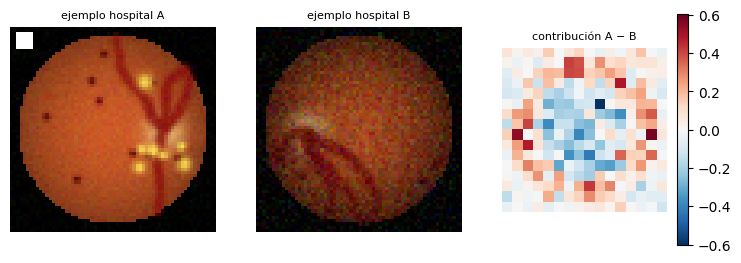

In [17]:
pesos = modelo_pix[-1].coef_.ravel()                       # un peso por píxel y canal
Z = modelo_pix[0].transform(aplanar(X_tr))                 # píxeles ya escalados
contrib = Z * pesos                                        # aportación de cada píxel en cada imagen
es_A = (tabla_tr["hospital"] == "A").values
mapa = (contrib[es_A].mean(0) - contrib[~es_A].mean(0))    # media en A menos media en B
mapa = mapa.reshape(64, 64, 3).sum(-1)                     # sumamos los 3 colores
mapa = mapa.reshape(16, 4, 16, 4).sum((1, 3))              # bloques de 4x4

lim = np.abs(mapa).max()
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
axs[0].imshow(X_tr[es_A][0]); axs[0].set_title("ejemplo hospital A", fontsize=8)
axs[1].imshow(X_tr[~es_A][0]); axs[1].set_title("ejemplo hospital B", fontsize=8)
im = axs[2].imshow(mapa, cmap="RdBu_r", vmin=-lim, vmax=lim); axs[2].set_title("contribución A − B", fontsize=8)
[a.axis("off") for a in axs]; plt.colorbar(im, ax=axs[2]); plt.show()

### 🤔 Para pensar

1. ¿Las zonas rojas coinciden con **lesiones** (que aparecen en sitios distintos en cada paciente) o con zonas **fijas** de la imagen?
2. Compara con los ejemplos de A y B: ¿qué diferencia hay en la **periferia del disco**? (Pista: el viñeteado de B.)
3. La marca blanca separa A y B a la perfección, pero ocupa solo 25 píxeles. ¿Dónde aparece en el mapa?

Un modelo lineal sobre píxeles **no puede** reconocer una mancha que cambia de sitio en cada imagen. Lo que sí puede aprender son las zonas fijas, y las únicas zonas fijas que cambian con la etiqueta son… las del escáner.

---
## Parte 6 · La prueba definitiva: pacientes sanos

Si el modelo mira el escáner, debería decir "referable" a pacientes **completamente sanos** solo por venir del hospital A. Gracias al generador podemos comprobarlo directamente con una intervención: $do(\text{gravedad}=0)$.

### ✏️ Ejercicio 6.1

Para cada hospital `h` (`"A"` y `"B"`):
1. Genera 300 pacientes sanos con `generar_dataset(range(500000, 500300), do={"gravedad": 0, "hospital": h})`.
2. Calcula la **fracción que el modelo predice como referable**: la media de `modelo_pix.predict(aplanar(X))`.

Guarda los resultados en el diccionario `sanos_pred`, de la forma `{"A": ..., "B": ...}`.

In [18]:
sanos_pred = {}
for h in ["A", "B"]:
    X, _ = generar_dataset(range(500000, 500300), do={"gravedad": 0, "hospital": h})
    sanos_pred[h] = modelo_pix.predict(aplanar(X)).mean()
for h, v in sanos_pred.items():
    print(f"Pacientes SANOS del hospital {h}: el modelo dice 'referable' al {v:.0%}")

Pacientes SANOS del hospital A: el modelo dice 'referable' al 82%
Pacientes SANOS del hospital B: el modelo dice 'referable' al 12%


In [19]:
# ✅ Comprobación
assert sanos_pred["A"] - sanos_pred["B"] > 0.3
print("✅ Atajo demostrado: los MISMOS ojos sanos reciben diagnósticos distintos según el escáner.")

✅ Atajo demostrado: los MISMOS ojos sanos reciben diagnósticos distintos según el escáner.


### 🤔 Para pensar

Has usado **los mismos 300 pacientes** (mismas semillas, así que mismos ojos) en los dos hospitales. ¿Podrías hacer este experimento con pacientes reales? ¿Qué tendrías que hacer?

Esto es exactamente lo que hace valioso un generador causal: puedes hacer preguntas de tipo $do(\cdot)$ que con datos reales serían carísimas o imposibles.

---
## Resumen

| Concepto | Lo que has visto |
|---|---|
| `fit` / `predict` / `score` | La API común de todos los modelos de `scikit-learn` |
| `reshape` | Convertir imágenes en vectores |
| `StandardScaler` + `make_pipeline` | Escalar y entrenar en un solo objeto |
| Balanced accuracy | No dejarse engañar por clases desequilibradas |
| Evaluar en varios mundos | Un buen resultado en iid **no garantiza nada** |
| Mapa de contribuciones | El modelo mira zonas fijas del escáner, no las lesiones |
| Pacientes sanos con $do(\cdot)$ | La prueba directa del atajo |

**Frase para tu README:** *"Un clasificador con un 76 % de balanced accuracy en test iid cae por debajo del azar en un hospital con otra prevalencia, y diagnostica como referables al 80 % de los ojos sanos del hospital A."* Comprueba tus números exactos arriba.

### Siguiente: notebook 05 · Contrafactuales y soluciones

Medirás el atajo paciente a paciente con contrafactuales y probarás dos formas de arreglarlo.